# Product Clustering 

## 1. Load Data for Product Clustering

### Objective
Create product-level behavioural profiles that summarize how each SKU behaves
across the historical period.

### Reasoning
Clustering should group products based on their overall behaviour rather than
individual weekly observations. Therefore, weekly records are aggregated into
one profile per SKU before applying K-Means.

In [6]:
import pandas as pd
import numpy as np

file_path = (
    "../data/raw/"
    "SmartMarkdown_Data_Dev_2024_2025.xlsx"
)

df = pd.read_excel(file_path)

df["Week_Start"] = pd.to_datetime(df["Week_Start"])

print("Shape:", df.shape)
print("Unique SKUs:", df["SKU_ID"].nunique())
print("Date Range:", df["Week_Start"].min(), "to", df["Week_Start"].max())

Shape: (4200, 30)
Unique SKUs: 40
Date Range: 2024-01-01 00:00:00 to 2025-12-29 00:00:00


## 2. Define SKU Behavioural Features

The clustering stage focuses on behavioural segmentation rather than prediction.

Each SKU will be represented using aggregate characteristics related to:

- demand level and variability
- discount behaviour
- inventory pressure
- sell-through
- customer engagement
- competitor pricing position

In [7]:
# ---------------------------------------------------------
# Aggregate Weekly Behaviour into One Profile per SKU
# ---------------------------------------------------------

sku_profile = (
    df.groupby("SKU_ID")
    .agg(
        Avg_Demand=("Latent_Demand", "mean"),
        Demand_Std=("Latent_Demand", "std"),

        Avg_Units_Sold=("Units_Sold", "mean"),

        Avg_Discount=("Discount_Pct", "mean"),
        Discount_Std=("Discount_Pct", "std"),

        Avg_Closing_Inventory=("Closing_Inventory", "mean"),
        Avg_Days_In_Inventory=("Days_In_Inventory", "mean"),

        Avg_Views=("Views", "mean"),
        Avg_Cart_Adds=("Cart_Adds", "mean"),

        Avg_Competitor_Gap=("Competitor_Price", "mean"),

        Stockout_Rate=("Stockout_Flag", "mean")
    )
    .reset_index()
)

print("SKU Profile Shape:", sku_profile.shape)

display(sku_profile.head())

SKU Profile Shape: (40, 12)


,SKU_ID,Avg_Demand,Demand_Std,Avg_Units_Sold,Avg_Discount,Discount_Std,Avg_Closing_Inventory,Avg_Days_In_Inventory,Avg_Views,Avg_Cart_Adds,Avg_Competitor_Gap,Stockout_Rate
0,SKU001,66.561905,12.939893,63.247619,15.333333,13.251754,224.552381,19.733333,1241.723810,146.238095,679.910952,0.057143
1,SKU002,62.895238,13.943515,62.685714,15.285714,12.145523,218.752381,20.466667,1185.323810,144.695238,845.820000,0.009524
2,SKU003,44.895238,11.505788,44.476190,16.857143,13.715116,146.038095,17.533333,842.914286,102.780952,1653.458571,0.019048
3,SKU004,37.466667,10.319014,37.047619,15.238095,12.313629,123.000000,19.266667,731.580952,87.904762,2112.250000,0.028571
4,SKU005,39.800000,8.100807,38.504762,15.666667,11.160255,125.428571,18.133333,726.685714,85.533333,2493.452381,0.038095


In [8]:
# Sell-through
df["Sell_Through"] = np.where(
    df["Available_Inventory"] > 0,
    df["Units_Sold"] / df["Available_Inventory"],
    0
)

# Competitor price position
df["Competitor_Gap_Pct"] = (
    (df["Selling_Price"] - df["Competitor_Price"])
    / df["Competitor_Price"]
    * 100
)

In [9]:
sku_profile = (
    df.groupby("SKU_ID")
    .agg(
        Avg_Demand=("Latent_Demand", "mean"),
        Demand_Std=("Latent_Demand", "std"),

        Avg_Units_Sold=("Units_Sold", "mean"),

        Avg_Discount=("Discount_Pct", "mean"),
        Discount_Std=("Discount_Pct", "std"),

        Avg_Closing_Inventory=("Closing_Inventory", "mean"),
        Avg_Days_In_Inventory=("Days_In_Inventory", "mean"),
        Avg_Sell_Through=("Sell_Through", "mean"),

        Avg_Views=("Views", "mean"),
        Avg_Cart_Adds=("Cart_Adds", "mean"),

        Avg_Competitor_Gap=("Competitor_Gap_Pct", "mean"),

        Stockout_Rate=("Stockout_Flag", "mean")
    )
    .reset_index()
)
print("SKU Profile Shape:", sku_profile.shape)

display(sku_profile.head())

SKU Profile Shape: (40, 13)


,SKU_ID,Avg_Demand,Demand_Std,Avg_Units_Sold,Avg_Discount,Discount_Std,Avg_Closing_Inventory,Avg_Days_In_Inventory,Avg_Sell_Through,Avg_Views,Avg_Cart_Adds,Avg_Competitor_Gap,Stockout_Rate
0,SKU001,66.561905,12.939893,63.247619,15.333333,13.251754,224.552381,19.733333,0.275993,1241.723810,146.238095,-0.519709,0.057143
1,SKU002,62.895238,13.943515,62.685714,15.285714,12.145523,218.752381,20.466667,0.265065,1185.323810,144.695238,0.213574,0.009524
2,SKU003,44.895238,11.505788,44.476190,16.857143,13.715116,146.038095,17.533333,0.279509,842.914286,102.780952,0.543479,0.019048
3,SKU004,37.466667,10.319014,37.047619,15.238095,12.313629,123.000000,19.266667,0.284524,731.580952,87.904762,0.435336,0.028571
4,SKU005,39.800000,8.100807,38.504762,15.666667,11.160255,125.428571,18.133333,0.295039,726.685714,85.533333,-0.047852,0.038095


In [10]:
# ---------------------------------------------------------
# SKU-Level Discount-Demand Relationship
# ---------------------------------------------------------

price_response = (
    df.groupby("SKU_ID")
    .apply(
        lambda x: x["Discount_Pct"].corr(
            x["Latent_Demand"]
        ),
        include_groups=False
    )
    .reset_index(name="Discount_Demand_Corr")
)

sku_profile = sku_profile.merge(
    price_response,
    on="SKU_ID",
    how="left"
)

display(
    sku_profile[
        ["SKU_ID", "Avg_Demand", "Avg_Discount", "Discount_Demand_Corr"]
    ].head()
)

,SKU_ID,Avg_Demand,Avg_Discount,Discount_Demand_Corr
0,SKU001,66.561905,15.333333,0.734870
1,SKU002,62.895238,15.285714,0.626153
2,SKU003,44.895238,16.857143,0.824142
3,SKU004,37.466667,15.238095,0.743742
4,SKU005,39.800000,15.666667,0.770979


In [11]:
print("Final SKU Profile Shape:", sku_profile.shape)

print("\nMissing Values:")
display(
    sku_profile
    .isnull()
    .sum()
    .to_frame("Missing_Count")
)

display(
    sku_profile.describe().T
)

Final SKU Profile Shape: (40, 14)

Missing Values:


,Missing_Count
SKU_ID,0
Avg_Demand,0
Demand_Std,0
Avg_Units_Sold,0
Avg_Discount,0
Discount_Std,0
Avg_Closing_Inventory,0
Avg_Days_In_Inventory,0
Avg_Sell_Through,0
Avg_Views,0


,count,mean,std,min,25%,50%,75%,max
Avg_Demand,40.0,38.015952,14.183023,9.190476,28.176190,36.452381,45.388095,75.942857
Demand_Std,40.0,8.726454,3.607573,1.911983,5.816975,8.482345,10.401296,17.479066
Avg_Units_Sold,40.0,37.172857,13.932482,9.190476,27.561905,35.542857,44.669048,74.761905
Avg_Discount,40.0,14.455952,1.929416,9.095238,13.369048,14.452381,15.809524,17.952381
Discount_Std,40.0,11.633871,1.381790,7.396106,10.958208,11.620342,12.631995,13.715116
Avg_Closing_Inventory,40.0,126.854762,47.173321,35.304762,96.135714,118.819048,148.233333,260.161905
Avg_Days_In_Inventory,40.0,18.675000,1.765073,14.466667,17.533333,18.666667,19.866667,22.933333
Avg_Sell_Through,40.0,0.272141,0.014634,0.238173,0.261765,0.274916,0.279758,0.298960
Avg_Views,40.0,725.154524,266.824296,179.580952,542.833333,694.314286,859.635714,1409.447619
Avg_Cart_Adds,40.0,86.481905,31.594196,21.838095,63.709524,84.380952,103.692857,165.295238


## 3. Clustering Feature Redundancy Audit

### Objective
Identify highly correlated behavioural variables before applying K-Means.

### Reasoning
K-Means is distance-based, so strongly redundant features can unintentionally
give certain behaviours extra influence on cluster formation.

The goal is not to remove every correlated feature, but to create a compact,
interpretable set of behavioural dimensions for product segmentation.

In [13]:
# ---------------------------------------------------------
# Correlation Audit for SKU Behavioural Features
# ---------------------------------------------------------

clustering_numeric_cols = [
    col for col in sku_profile.columns
    if col != "SKU_ID"
]

clustering_corr = (
    sku_profile[clustering_numeric_cols]
    .corr()
    .round(2)
)

display(clustering_corr)

,Avg_Demand,Demand_Std,Avg_Units_Sold,Avg_Discount,Discount_Std,Avg_Closing_Inventory,Avg_Days_In_Inventory,Avg_Sell_Through,Avg_Views,Avg_Cart_Adds,Avg_Competitor_Gap,Stockout_Rate,Discount_Demand_Corr
Avg_Demand,1.00,0.87,1.00,0.55,0.46,0.99,-0.08,0.36,1.00,1.00,-0.47,0.02,0.07
Demand_Std,0.87,1.00,0.88,0.69,0.59,0.84,-0.17,0.40,0.88,0.88,-0.35,-0.11,-0.25
Avg_Units_Sold,1.00,0.88,1.00,0.56,0.47,0.99,-0.09,0.35,1.00,1.00,-0.47,-0.03,0.08
Avg_Discount,0.55,0.69,0.56,1.00,0.85,0.50,-0.48,0.53,0.56,0.56,-0.48,-0.21,-0.18
Discount_Std,0.46,0.59,0.47,0.85,1.00,0.42,-0.49,0.42,0.47,0.48,-0.41,-0.34,-0.07
Avg_Closing_Inventory,0.99,0.84,0.99,0.50,0.42,1.00,-0.04,0.26,0.99,0.99,-0.46,-0.00,0.08
Avg_Days_In_Inventory,-0.08,-0.17,-0.09,-0.48,-0.49,-0.04,1.00,-0.15,-0.08,-0.08,0.30,0.36,-0.14
Avg_Sell_Through,0.36,0.40,0.35,0.53,0.42,0.26,-0.15,1.00,0.35,0.35,-0.24,0.25,0.03
Avg_Views,1.00,0.88,1.00,0.56,0.47,0.99,-0.08,0.35,1.00,1.00,-0.46,0.01,0.06
Avg_Cart_Adds,1.00,0.88,1.00,0.56,0.48,0.99,-0.08,0.35,1.00,1.00,-0.46,0.01,0.06


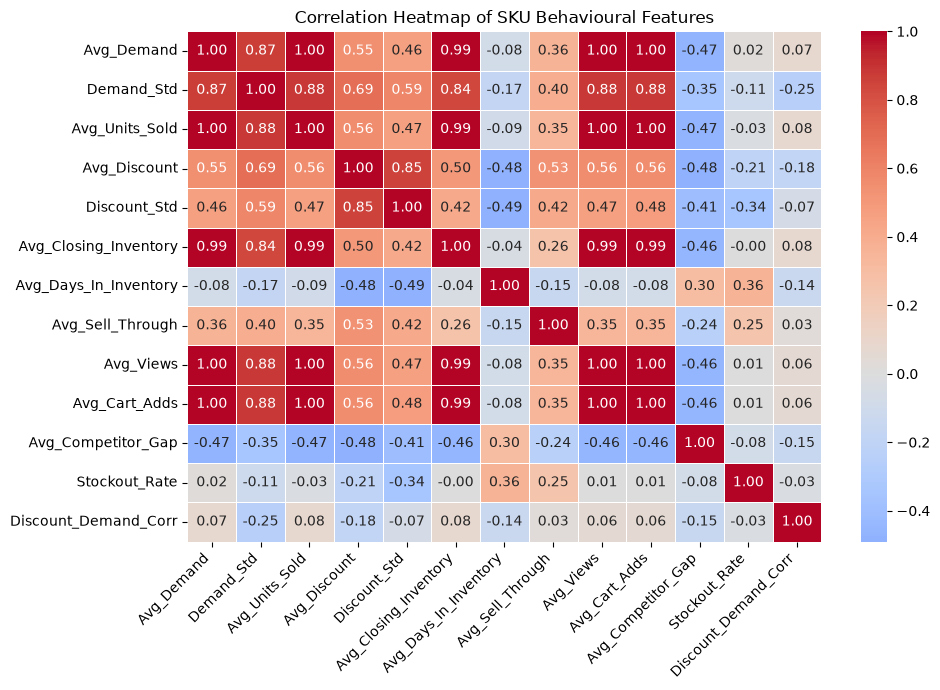

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 7))

sns.heatmap(
    clustering_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)
plt.xticks(rotation=45, ha="right")
plt.title("Correlation Heatmap of SKU Behavioural Features")
plt.tight_layout()

plt.savefig(
    "../outputs/charts/clustering/sku_behavior_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [15]:
import os

os.makedirs(
    "../outputs/charts/clustering",
    exist_ok=True
)

In [19]:
high_corr_pairs = []

for i in range(len(clustering_corr.columns)):
    for j in range(i + 1, len(clustering_corr.columns)):

        corr_value = clustering_corr.iloc[i, j]

        if abs(corr_value) >= 0.80:

            high_corr_pairs.append({
                "Feature_1": clustering_corr.columns[i],
                "Feature_2": clustering_corr.columns[j],
                "Correlation": corr_value
            })

clustering_high_corr_df = pd.DataFrame(
    high_corr_pairs
)

display(
    clustering_high_corr_df.sort_values(
        "Correlation",
        key=abs,
        ascending=False
    )
)

,Feature_1,Feature_2,Correlation
1,Avg_Demand,Avg_Units_Sold,1.00
3,Avg_Demand,Avg_Views,1.00
4,Avg_Demand,Avg_Cart_Adds,1.00
11,Avg_Units_Sold,Avg_Cart_Adds,1.00
10,Avg_Units_Sold,Avg_Views,1.00
15,Avg_Views,Avg_Cart_Adds,1.00
9,Avg_Units_Sold,Avg_Closing_Inventory,0.99
2,Avg_Demand,Avg_Closing_Inventory,0.99
14,Avg_Closing_Inventory,Avg_Cart_Adds,0.99
13,Avg_Closing_Inventory,Avg_Views,0.99


In [20]:
# ---------------------------------------------------------
# Relative Demand Variability
# ---------------------------------------------------------

sku_profile["Demand_CV"] = (
    sku_profile["Demand_Std"]
    / sku_profile["Avg_Demand"]
)

## 4. Final Clustering Feature Selection

### Objective
Select a compact and interpretable feature set for SKU behavioural clustering.

### Reasoning
Several SKU-level variables are highly correlated. Avg_Demand, Avg_Units_Sold,
Avg_Views, Avg_Cart_Adds and Avg_Closing_Inventory largely represent the same
underlying product-volume behaviour.

Including all of them would give demand/popularity excessive influence in the
distance calculations used by K-Means.

Therefore, one representative feature is retained for each important behavioural
dimension.

Demand variability is represented using the coefficient of variation (Demand_CV)
rather than absolute standard deviation so that volatility is measured relative
to each SKU's average demand.

In [21]:
clustering_features = [
    "Avg_Demand",
    "Demand_CV",
    "Avg_Discount",
    "Avg_Days_In_Inventory",
    "Avg_Sell_Through",
    "Avg_Competitor_Gap",
    "Stockout_Rate",
    "Discount_Demand_Corr"
]

print("Number of Clustering Features:", len(clustering_features))

display(
    sku_profile[
        ["SKU_ID"] + clustering_features
    ].head()
)

Number of Clustering Features: 8


,SKU_ID,Avg_Demand,Demand_CV,Avg_Discount,Avg_Days_In_Inventory,Avg_Sell_Through,Avg_Competitor_Gap,Stockout_Rate,Discount_Demand_Corr
0,SKU001,66.561905,0.194404,15.333333,19.733333,0.275993,-0.519709,0.057143,0.734870
1,SKU002,62.895238,0.221694,15.285714,20.466667,0.265065,0.213574,0.009524,0.626153
2,SKU003,44.895238,0.256281,16.857143,17.533333,0.279509,0.543479,0.019048,0.824142
3,SKU004,37.466667,0.275419,15.238095,19.266667,0.284524,0.435336,0.028571,0.743742
4,SKU005,39.800000,0.203538,15.666667,18.133333,0.295039,-0.047852,0.038095,0.770979


In [22]:
selected_clustering_corr = (
    sku_profile[clustering_features]
    .corr()
    .round(2)
)

display(selected_clustering_corr)

,Avg_Demand,Demand_CV,Avg_Discount,Avg_Days_In_Inventory,Avg_Sell_Through,Avg_Competitor_Gap,Stockout_Rate,Discount_Demand_Corr
Avg_Demand,1.00,-0.03,0.55,-0.08,0.36,-0.47,0.02,0.07
Demand_CV,-0.03,1.00,0.38,-0.18,0.16,0.14,-0.21,-0.69
Avg_Discount,0.55,0.38,1.00,-0.48,0.53,-0.48,-0.21,-0.18
Avg_Days_In_Inventory,-0.08,-0.18,-0.48,1.00,-0.15,0.30,0.36,-0.14
Avg_Sell_Through,0.36,0.16,0.53,-0.15,1.00,-0.24,0.25,0.03
Avg_Competitor_Gap,-0.47,0.14,-0.48,0.30,-0.24,1.00,-0.08,-0.15
Stockout_Rate,0.02,-0.21,-0.21,0.36,0.25,-0.08,1.00,-0.03
Discount_Demand_Corr,0.07,-0.69,-0.18,-0.14,0.03,-0.15,-0.03,1.00


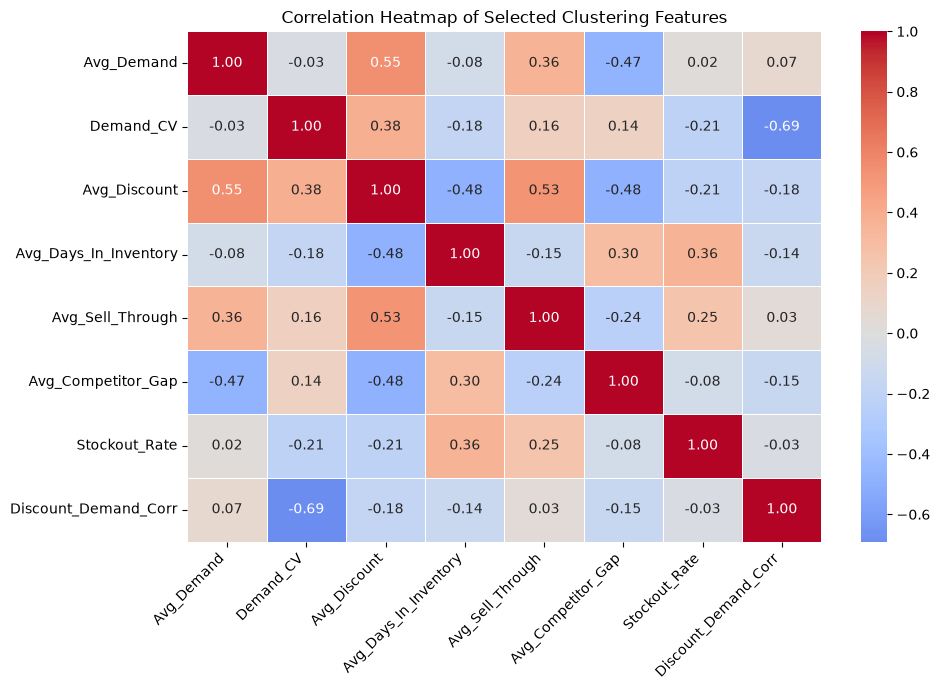

In [24]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    selected_clustering_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)
plt.xticks(rotation=45, ha="right")
plt.title("Correlation Heatmap of Selected Clustering Features")
plt.tight_layout()
plt.show()

### Selected Clustering Feature Review

The reduced clustering feature set shows substantially lower redundancy than the
original SKU profile.

No near-perfect correlations remain among the selected variables. The strongest
relationship is between Demand_CV and Discount_Demand_Corr, but both are retained
because they represent different business behaviours.

The final feature set provides a balanced representation of demand, volatility,
markdown behaviour, inventory movement, competitive positioning and stockout risk.

## 5. Feature Scaling

### Objective
Standardize the selected behavioural features before K-Means clustering.

### Reasoning
K-Means uses Euclidean distance. Since the selected features have different units
and numerical ranges, StandardScaler is applied so each feature contributes on a
comparable scale to cluster formation.

In [25]:
from sklearn.preprocessing import StandardScaler

# ---------------------------------------------------------
# Standardize Clustering Features
# ---------------------------------------------------------

X_cluster = sku_profile[clustering_features].copy()

scaler = StandardScaler()

X_cluster_scaled = scaler.fit_transform(
    X_cluster
)

print("Original Shape:", X_cluster.shape)
print("Scaled Shape:", X_cluster_scaled.shape)

Original Shape: (40, 8)
Scaled Shape: (40, 8)


In [26]:
scaled_df = pd.DataFrame(
    X_cluster_scaled,
    columns=clustering_features
)

display(
    scaled_df.describe().round(2)
)

,Avg_Demand,Demand_CV,Avg_Discount,Avg_Days_In_Inventory,Avg_Sell_Through,Avg_Competitor_Gap,Stockout_Rate,Discount_Demand_Corr
count,40.00,40.00,40.00,40.00,40.00,40.00,40.00,40.00
mean,0.00,-0.00,0.00,-0.00,0.00,0.00,0.00,-0.00
std,1.01,1.01,1.01,1.01,1.01,1.01,1.01,1.01
min,-2.06,-1.50,-2.81,-2.41,-2.35,-2.34,-1.56,-2.40
25%,-0.70,-0.70,-0.57,-0.66,-0.72,-0.59,-1.00,-0.17
50%,-0.11,-0.14,-0.00,-0.00,0.19,-0.07,0.11,0.24
75%,0.53,0.65,0.71,0.68,0.53,0.47,0.67,0.62
max,2.71,3.10,1.84,2.44,1.86,2.30,1.79,1.81


## 6. Determine the Optimal Number of Clusters

### Objective
Identify a suitable number of behavioural SKU clusters.

### Methods
Two complementary methods are used:

- **Elbow Method:** examines how within-cluster variation decreases as the
  number of clusters increases.
- **Silhouette Score:** measures how well separated and internally consistent
  the resulting clusters are.

Cluster counts from 2 to 6 are evaluated because the dataset contains only
40 SKUs and the final segmentation should remain interpretable.

In [27]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k_values = range(2, 7)

inertia_values = []
silhouette_values = []

for k in k_values:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    cluster_labels = kmeans.fit_predict(X_cluster_scaled)

    inertia_values.append(kmeans.inertia_)

    silhouette_values.append(
        silhouette_score(
            X_cluster_scaled,
            cluster_labels
        )
    )

cluster_evaluation = pd.DataFrame({
    "K": list(k_values),
    "Inertia": inertia_values,
    "Silhouette_Score": silhouette_values
})

display(cluster_evaluation.round(3))

,K,Inertia,Silhouette_Score
0,2,246.265,0.187
1,3,203.695,0.197
2,4,180.803,0.167
3,5,163.857,0.161
4,6,148.735,0.140


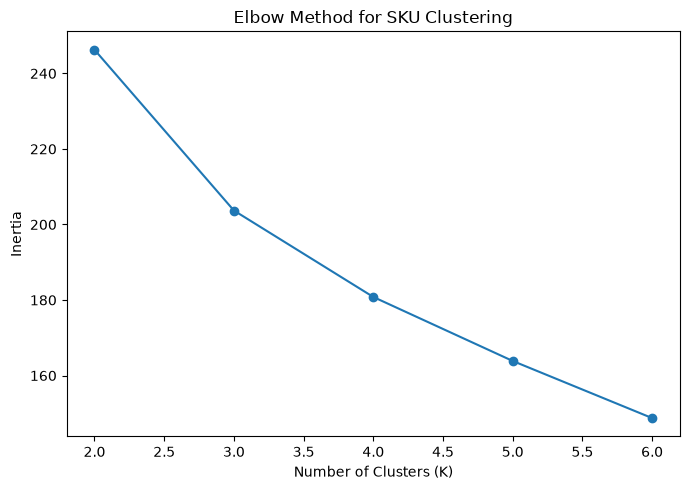

In [28]:
plt.figure(figsize=(7, 5))

plt.plot(
    list(k_values),
    inertia_values,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for SKU Clustering")

plt.tight_layout()

plt.savefig(
    "../outputs/charts/clustering/kmeans_elbow_plot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

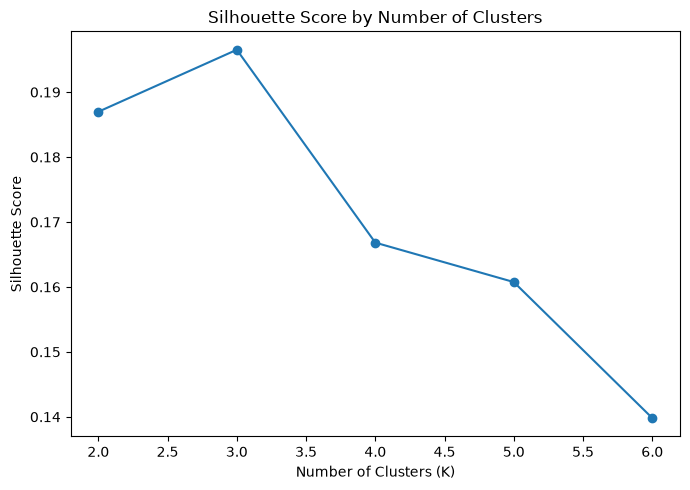

In [29]:
plt.figure(figsize=(7, 5))

plt.plot(
    list(k_values),
    silhouette_values,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score by Number of Clusters")

plt.tight_layout()

plt.savefig(
    "../outputs/charts/clustering/kmeans_silhouette_plot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Optimal Number of Clusters

The Elbow Method and Silhouette Score were evaluated for cluster counts from
K = 2 to K = 6.

The highest Silhouette Score was obtained at:

- K = 3
- Silhouette Score = 0.197

The elbow curve also shows a noticeable reduction in improvement after K = 3.

Therefore, K = 3 is selected as the initial number of SKU behavioural clusters.

The relatively moderate Silhouette Score indicates that product behaviours overlap
to some extent, so cluster interpretation and business usefulness will also be
considered before finalizing the segmentation.

In [30]:
# ---------------------------------------------------------
# Final K-Means Clustering
# ---------------------------------------------------------

final_kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=20
)

sku_profile["Cluster"] = final_kmeans.fit_predict(
    X_cluster_scaled
)

print("Cluster Distribution:")
display(
    sku_profile["Cluster"]
    .value_counts()
    .sort_index()
    .to_frame("SKU_Count")
)

Cluster Distribution:


,SKU_Count
Cluster,
0,14
1,8
2,18


In [31]:
display(
    sku_profile[
        ["SKU_ID", "Cluster"]
    ]
    .sort_values(
        ["Cluster", "SKU_ID"]
    )
)

,SKU_ID,Cluster
7,SKU008,0
8,SKU009,0
9,SKU010,0
16,SKU017,0
18,SKU019,0
20,SKU021,0
21,SKU022,0
22,SKU023,0
23,SKU024,0
25,SKU026,0


In [32]:
cluster_profile = (
    sku_profile
    .groupby("Cluster")[clustering_features]
    .mean()
    .round(3)
)

display(cluster_profile)

,Avg_Demand,Demand_CV,Avg_Discount,Avg_Days_In_Inventory,Avg_Sell_Through,Avg_Competitor_Gap,Stockout_Rate,Discount_Demand_Corr
Cluster,,,,,,,,
0,30.444,0.190,12.520,19.519,0.263,0.866,0.029,0.779
1,34.146,0.299,15.208,18.992,0.270,0.425,0.030,0.547
2,45.625,0.230,15.627,17.878,0.280,0.045,0.024,0.761


### Cluster Interpretation

Three behavioural SKU segments were identified:

#### Cluster 0 — Slow-Moving Markdown-Responsive
- Lower average demand
- Higher inventory ageing
- Lower sell-through
- Slightly higher competitor price gap
- Strong historical discount-demand relationship

These SKUs may benefit from targeted markdowns to improve inventory movement.

#### Cluster 1 — Volatile Low-Response
- Moderate demand
- Highest demand variability
- Moderate inventory movement
- Weakest historical response to markdowns

Markdown recommendations for these SKUs should be more cautious because demand
is volatile and deeper discounts may not consistently generate sufficient uplift.

#### Cluster 2 — High-Demand Fast-Moving
- Highest average demand
- Highest sell-through
- Lowest inventory ageing
- Competitive pricing
- Strong historical markdown response

These SKUs already demonstrate healthy demand and inventory movement, so aggressive
markdowns may be unnecessary and could reduce profitability.

In [33]:
cluster_labels = {
    0: "Slow-Moving Markdown-Responsive",
    1: "Volatile Low-Response",
    2: "High-Demand Fast-Moving"
}

sku_profile["Cluster_Label"] = (
    sku_profile["Cluster"]
    .map(cluster_labels)
)

display(
    sku_profile[
        [
            "SKU_ID",
            "Cluster",
            "Cluster_Label"
        ]
    ].sort_values(
        ["Cluster", "SKU_ID"]
    )
)

,SKU_ID,Cluster,Cluster_Label
7,SKU008,0,Slow-Moving Markdown-Responsive
8,SKU009,0,Slow-Moving Markdown-Responsive
9,SKU010,0,Slow-Moving Markdown-Responsive
16,SKU017,0,Slow-Moving Markdown-Responsive
18,SKU019,0,Slow-Moving Markdown-Responsive
20,SKU021,0,Slow-Moving Markdown-Responsive
21,SKU022,0,Slow-Moving Markdown-Responsive
22,SKU023,0,Slow-Moving Markdown-Responsive
23,SKU024,0,Slow-Moving Markdown-Responsive
25,SKU026,0,Slow-Moving Markdown-Responsive


In [34]:
# ---------------------------------------------------------
# Standardized Cluster Profile for Interpretation
# ---------------------------------------------------------

scaled_profile_df = pd.DataFrame(
    X_cluster_scaled,
    columns=clustering_features
)

scaled_profile_df["Cluster"] = (
    sku_profile["Cluster"].values
)

cluster_profile_scaled = (
    scaled_profile_df
    .groupby("Cluster")
    .mean()
)

display(
    cluster_profile_scaled.round(2)
)

,Avg_Demand,Demand_CV,Avg_Discount,Avg_Days_In_Inventory,Avg_Sell_Through,Avg_Competitor_Gap,Stockout_Rate,Discount_Demand_Corr
Cluster,,,,,,,,
0,-0.54,-0.81,-1.02,0.48,-0.61,0.63,0.11,0.52
1,-0.28,1.41,0.39,0.18,-0.15,0.02,0.18,-1.71
2,0.54,0.00,0.61,-0.46,0.54,-0.50,-0.17,0.35


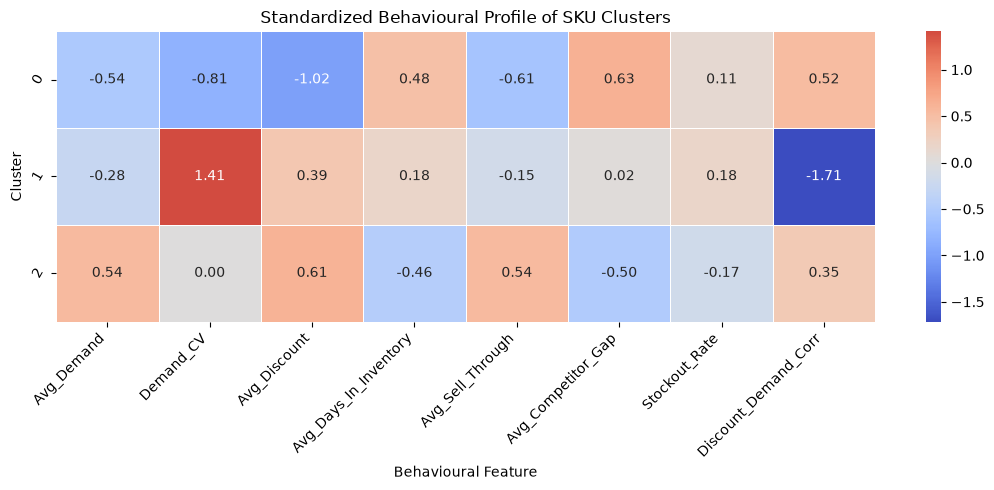

In [40]:
plt.figure(figsize=(11, 5))

sns.heatmap(
    cluster_profile_scaled,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=60, ha="right")
plt.title("Standardized Behavioural Profile of SKU Clusters")
plt.xlabel("Behavioural Feature")
plt.ylabel("Cluster")

plt.tight_layout()

plt.savefig(
    "../outputs/charts/clustering/cluster_behavior_profile.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Standardized Cluster Profile Interpretation

The standardized cluster heatmap confirms clear behavioural differences between
the three SKU segments.

- Cluster 0 shows below-average demand and sell-through, higher inventory ageing,
  and strong markdown responsiveness.
- Cluster 1 is characterized by high demand volatility and the weakest markdown
  response.
- Cluster 2 shows above-average demand and sell-through, lower inventory ageing,
  competitive pricing and healthy markdown responsiveness.

These patterns support the assigned business labels and make the clusters suitable
for downstream markdown decision logic.

In [41]:
cluster_mapping = sku_profile[
    [
        "SKU_ID",
        "Cluster",
        "Cluster_Label"
    ]
].copy()

cluster_mapping.to_csv(
    "../data/processed/smartmarkdown_sku_cluster_mapping.csv",
    index=False
)

print("Cluster mapping saved successfully.")

Cluster mapping saved successfully.


In [42]:
import joblib

joblib.dump(
    scaler,
    "../models/smartmarkdown_cluster_scaler.joblib"
)

joblib.dump(
    final_kmeans,
    "../models/smartmarkdown_kmeans_model.joblib"
)

print("Clustering scaler and K-Means model saved successfully.")

Clustering scaler and K-Means model saved successfully.


In [43]:
cluster_metadata = {
    "n_clusters": 3,
    "clustering_features": clustering_features,
    "cluster_labels": cluster_labels,
    "silhouette_score": 0.197
}

joblib.dump(
    cluster_metadata,
    "../models/smartmarkdown_clustering_metadata.joblib"
)

print("Clustering metadata saved successfully.")

Clustering metadata saved successfully.


## 7. Product Clustering — Final Summary

- SKU-level behavioural profiles were created using the complete 2024–2025 history.
- Highly redundant variables were removed before clustering.
- Eight behavioural features were selected and standardized.
- Elbow Method and Silhouette Score supported K = 3.
- K-Means clustering identified three interpretable SKU segments:

  1. Slow-Moving Markdown-Responsive
  2. Volatile Low-Response
  3. High-Demand Fast-Moving

- Cluster mapping, scaler, K-Means model and metadata were saved for downstream use.

**Next Stage:** Price Response and Prediction Uncertainty